In [2]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import SimpleITK as sitk

from src.models.unet_3d_monai import UNet3D_MONAI
from src.data.io_utils import read_tif_image, convert_image_to_array
from src.data.dataset_2class import create_datasets_2class


model_path = project_root / "outputs" / "unet_2class_slices40" / "checkpoints" / "best_model.pth"
log_path = project_root / "outputs" / "unet_2class_slices40" / "logs" / "training.csv"
df = pd.read_csv(log_path)

print(f"Logs chargés: {len(df)} époques")
print(f"Colonnes: {list(df.columns)}")

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Chargement du modèle...")
checkpoint = torch.load(model_path, map_location=device)

model = UNet3D_MONAI(
    in_channels=1,
    out_channels=2,
    init_features=32
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print(f"✅ Modèle chargé sur {device}")
print(f"   Époque: {checkpoint.get('epoch', 'N/A')}")
print(f"   Meilleur score: {checkpoint.get('best_score', 'N/A')}")

Logs chargés: 21 époques
Colonnes: ['epoch', 'train_loss', 'train_dice', 'train_iou', 'train_accuracy', 'train_f1', 'train_recall', 'train_precision', 'val_loss', 'val_dice', 'val_iou', 'val_accuracy', 'val_f1', 'val_recall', 'val_precision', 'epoch_time_seconds', 'train_time_seconds', 'val_time_seconds', 'gpu_memory_mb']
Chargement du modèle...
✅ Modèle chargé sur cuda
   Époque: 17
   Meilleur score: 0.49399090577394533


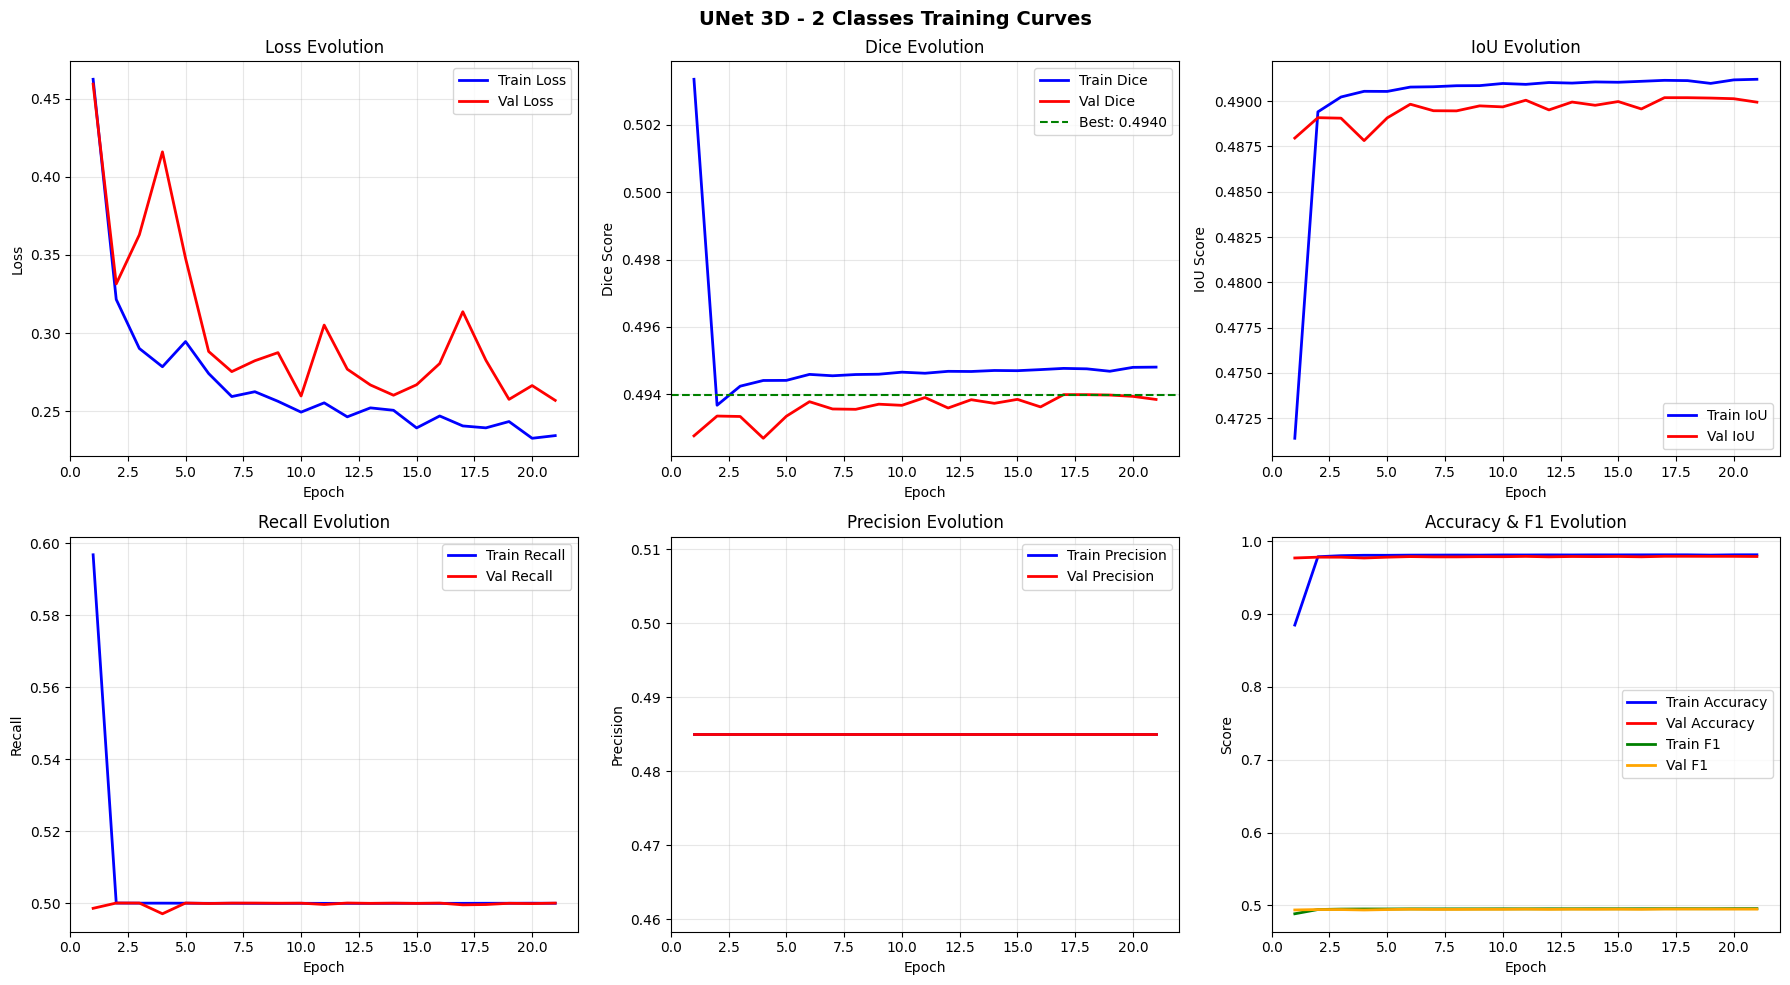

In [3]:

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

epochs = df['epoch'].values

axes[0, 0].plot(epochs, df['train_loss'], 'b-', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs, df['val_loss'], 'r-', label='Val Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Loss Evolution')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(epochs, df['train_dice'], 'b-', label='Train Dice', linewidth=2)
axes[0, 1].plot(epochs, df['val_dice'], 'r-', label='Val Dice', linewidth=2)
axes[0, 1].axhline(y=df['val_dice'].max(), color='green', linestyle='--', label=f"Best: {df['val_dice'].max():.4f}")
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Dice Score')
axes[0, 1].set_title('Dice Evolution')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].plot(epochs, df['train_iou'], 'b-', label='Train IoU', linewidth=2)
axes[0, 2].plot(epochs, df['val_iou'], 'r-', label='Val IoU', linewidth=2)
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('IoU Score')
axes[0, 2].set_title('IoU Evolution')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

axes[1, 0].plot(epochs, df['train_recall'], 'b-', label='Train Recall', linewidth=2)
axes[1, 0].plot(epochs, df['val_recall'], 'r-', label='Val Recall', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Recall')
axes[1, 0].set_title('Recall Evolution')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(epochs, df['train_precision'], 'b-', label='Train Precision', linewidth=2)
axes[1, 1].plot(epochs, df['val_precision'], 'r-', label='Val Precision', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Precision')
axes[1, 1].set_title('Precision Evolution')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(epochs, df['train_accuracy'], 'b-', label='Train Accuracy', linewidth=2)
axes[1, 2].plot(epochs, df['val_accuracy'], 'r-', label='Val Accuracy', linewidth=2)
axes[1, 2].plot(epochs, df['train_f1'], 'g-', label='Train F1', linewidth=2)
axes[1, 2].plot(epochs, df['val_f1'], 'orange', label='Val F1', linewidth=2)
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Score')
axes[1, 2].set_title('Accuracy & F1 Evolution')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.suptitle('UNet 3D - 2 Classes Training Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(project_root / "outputs" / "unet_2class_slices40" / "training_curves.png", dpi=150, bbox_inches='tight')
plt.show()


In [4]:

best_epoch = df.loc[df['val_dice'].idxmax()]
print("=" * 60)
print("STATISTIQUES RÉCAPITULATIVES - UNET 3D 2 CLASSES")
print("=" * 60)
print(f"Nombre d'époques: {len(df)}")
print(f"Meilleure époque: {int(best_epoch['epoch'])}")
print()
print("Meilleures métriques de validation:")
print(f"  Val Dice: {best_epoch['val_dice']:.4f}")
print(f"  Val IoU: {best_epoch['val_iou']:.4f}")
print(f"  Val Accuracy: {best_epoch['val_accuracy']:.4f}")
print(f"  Val Recall: {best_epoch['val_recall']:.4f}")
print(f"  Val Precision: {best_epoch['val_precision']:.4f}")
print(f"  Val F1: {best_epoch['val_f1']:.4f}")
print()
print("Métriques finales (dernière époque):")
print(f"  Val Dice: {df['val_dice'].iloc[-1]:.4f}")
print(f"  Val IoU: {df['val_iou'].iloc[-1]:.4f}")
print(f"  Val Loss: {df['val_loss'].iloc[-1]:.4f}")
print(f"  Train Loss: {df['train_loss'].iloc[-1]:.4f}")
print()
print("Temps d'entraînement:")
print(f"  Total temps: {df['epoch_time_seconds'].sum()/3600:.2f} heures")
print(f"  Moyenne par époque: {df['epoch_time_seconds'].mean()/60:.2f} minutes")
print(f"  GPU Memory: {df['gpu_memory_mb'].max():.2f} MB")

STATISTIQUES RÉCAPITULATIVES - UNET 3D 2 CLASSES
Nombre d'époques: 21
Meilleure époque: 17

Meilleures métriques de validation:
  Val Dice: 0.4940
  Val IoU: 0.4902
  Val Accuracy: 0.9792
  Val Recall: 0.4995
  Val Precision: 0.4850
  Val F1: 0.4951

Métriques finales (dernière époque):
  Val Dice: 0.4938
  Val IoU: 0.4899
  Val Loss: 0.2570
  Train Loss: 0.2344

Temps d'entraînement:
  Total temps: 16.00 heures
  Moyenne par époque: 45.70 minutes
  GPU Memory: 299.66 MB


CREATING DATASETS (2 CLASSES)
Data directory: /mnt/x/donnees/pachs_64_2classes_slices40
Splits directory: /mnt/x/donnees/pachs_64_2classes_slices40/splits

  Dataset chargé: 4945 patches
  Dataset chargé: 618 patches
  Dataset chargé: 619 patches

Train dataset: 4945 samples
Val dataset: 618 samples
Test dataset: 619 samples

Nombre de patches de test: 619
Visualisation des prédictions sur le test set (seuil=0.4)...


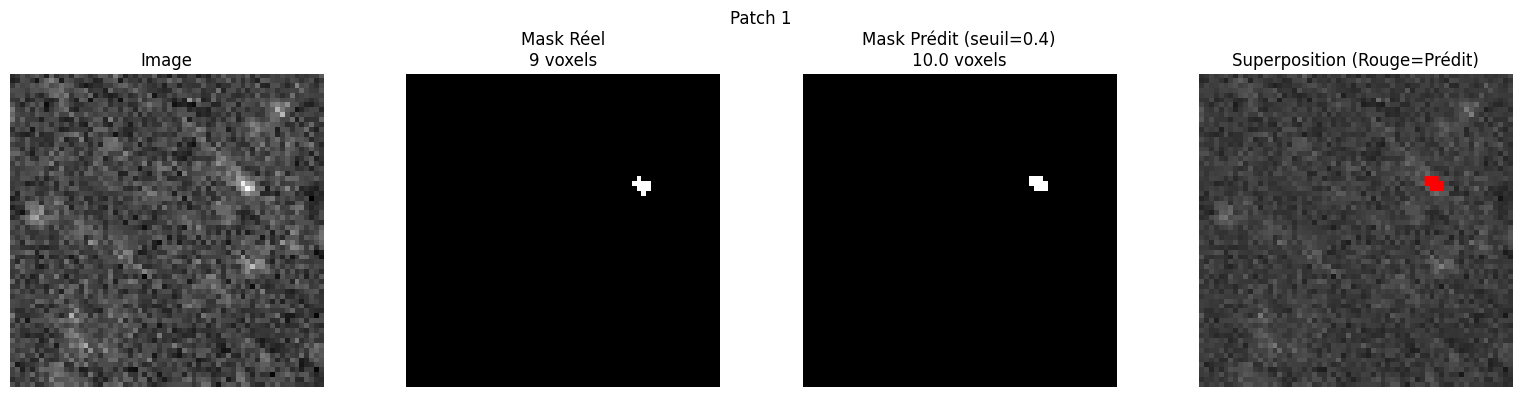

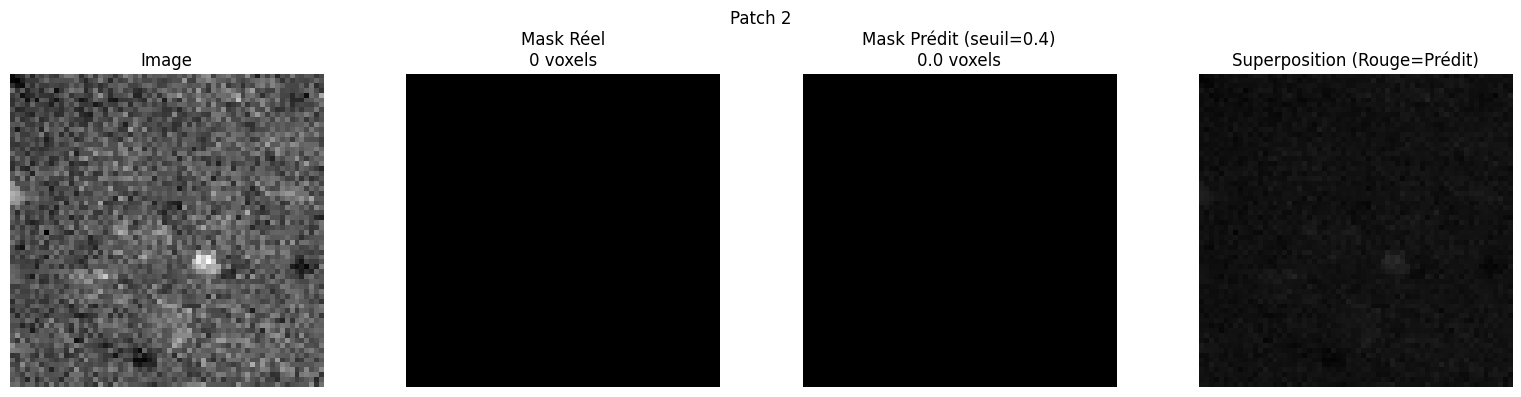

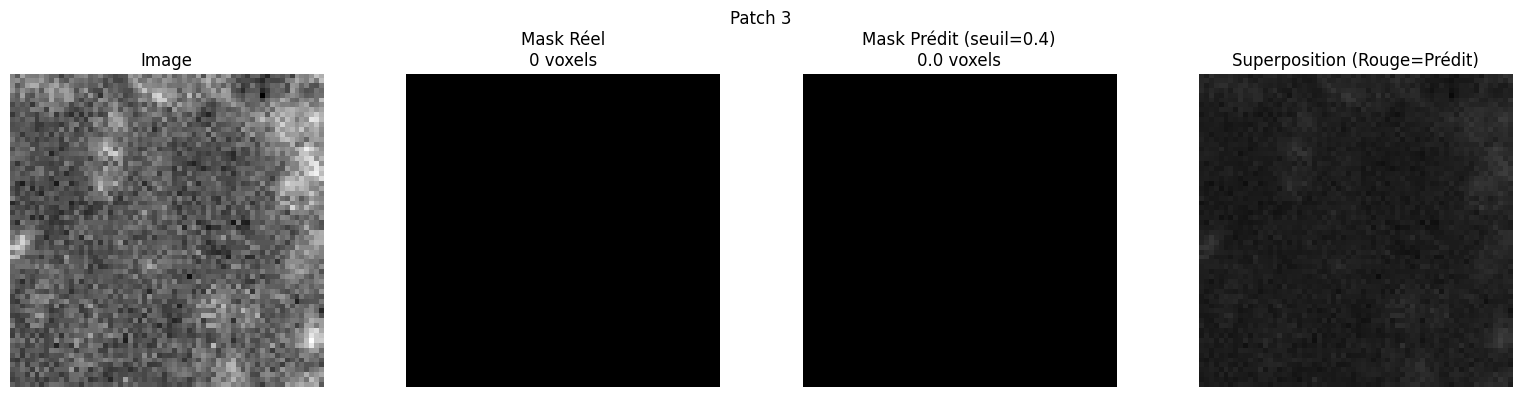

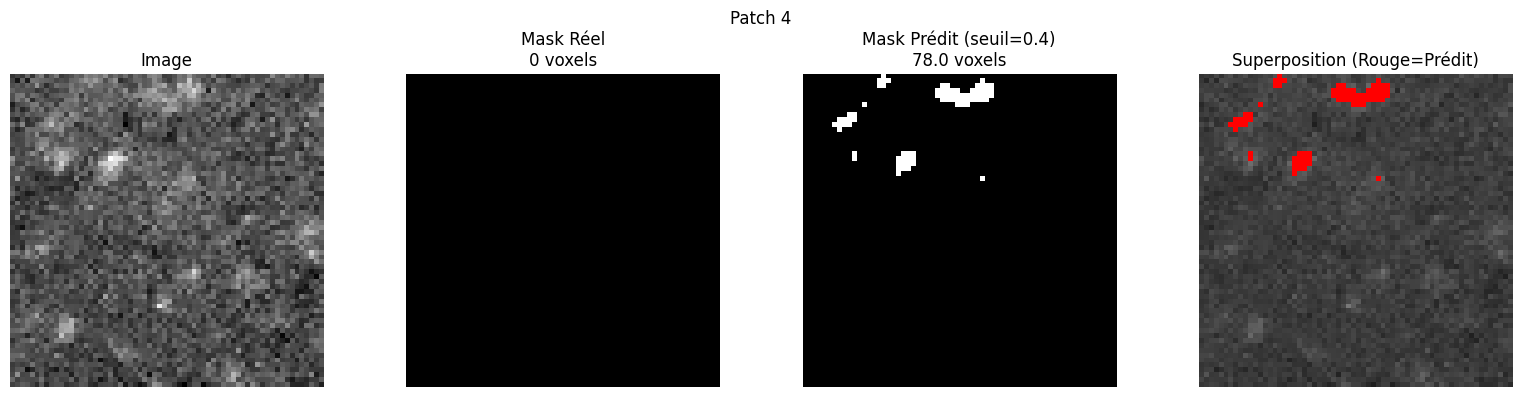

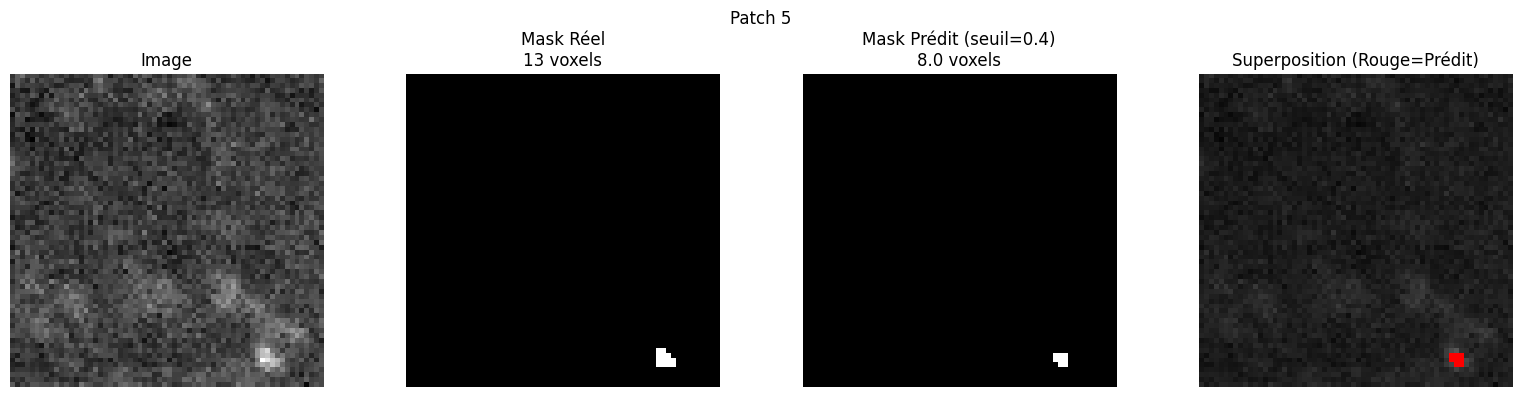

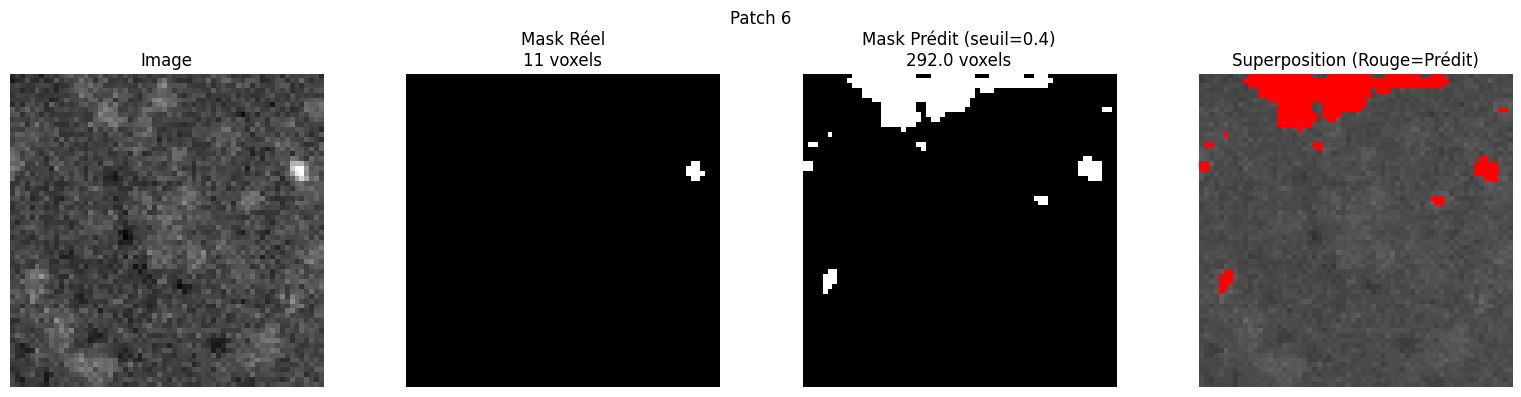

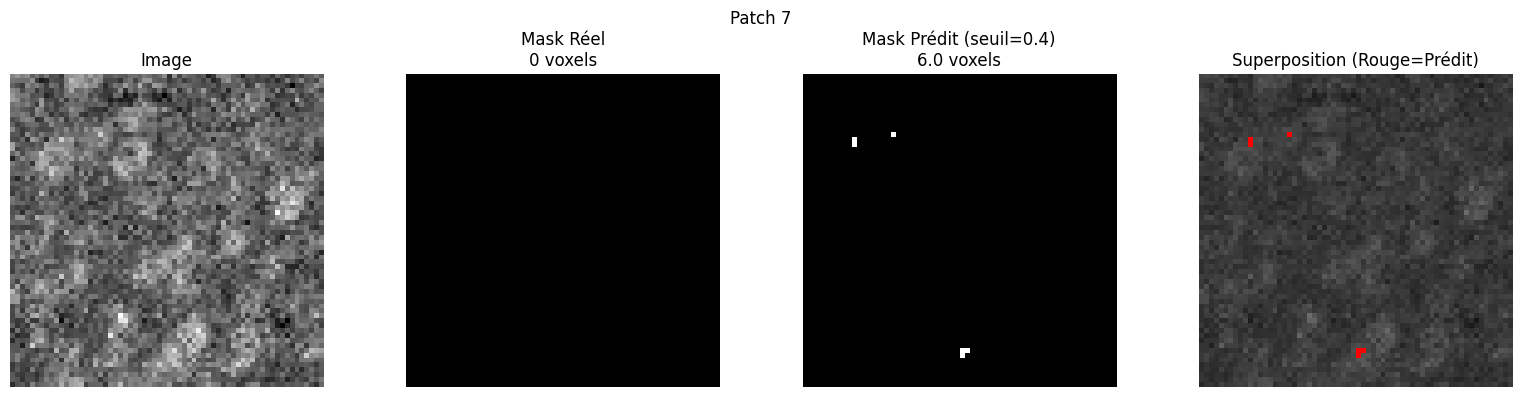

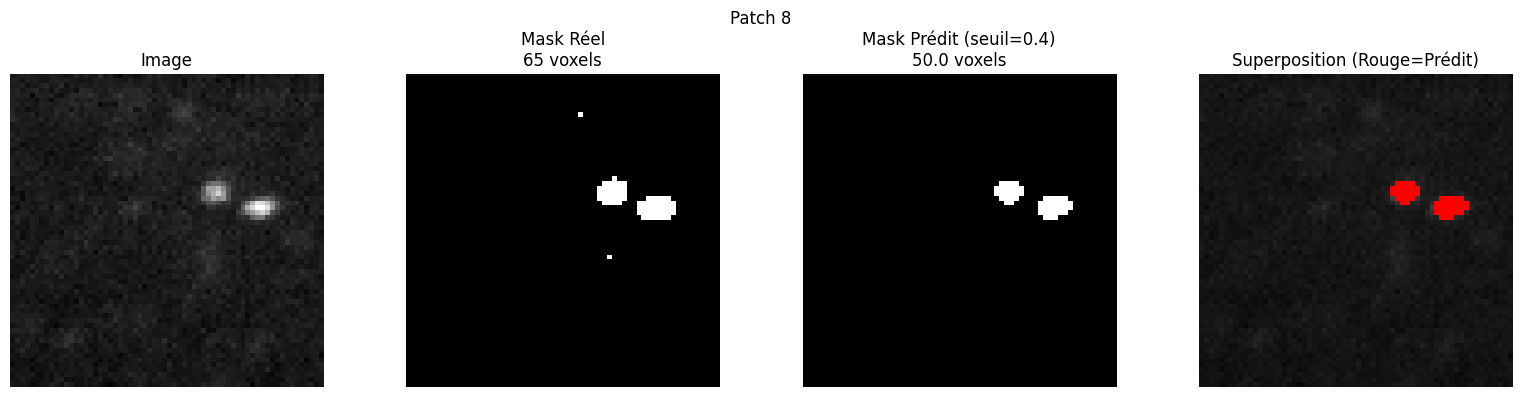

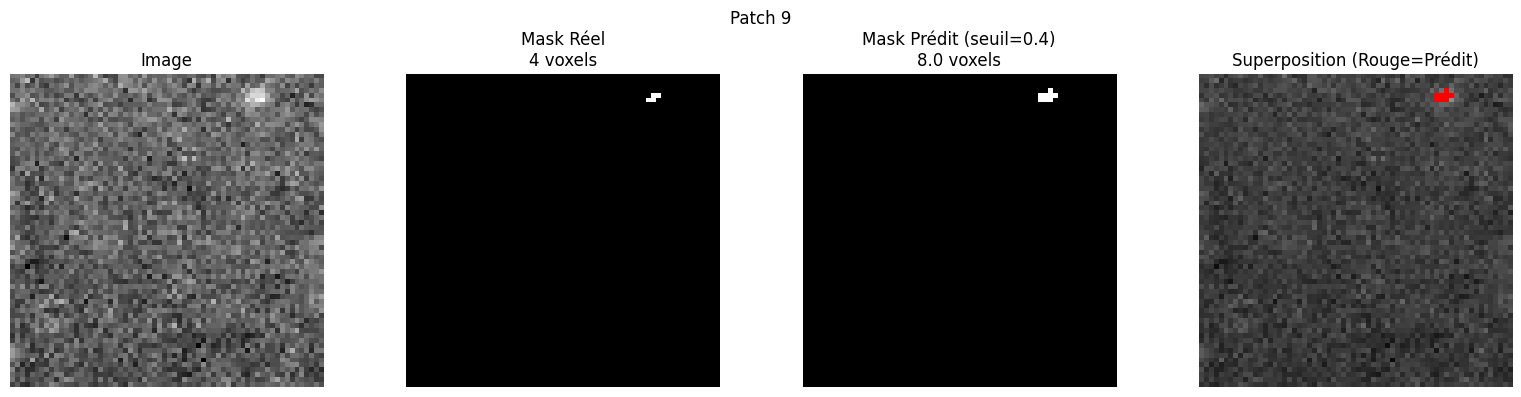

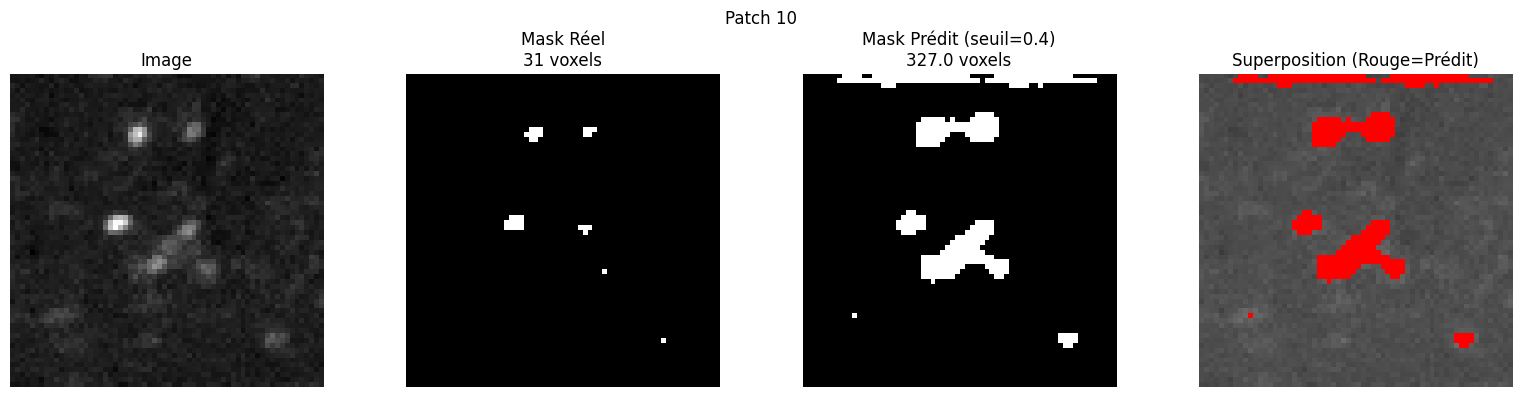

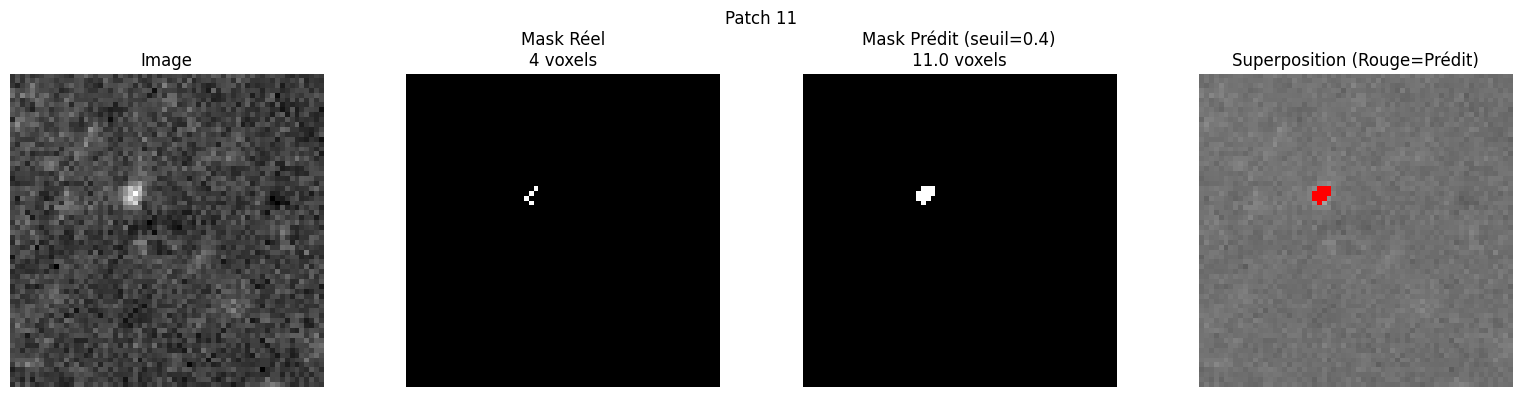

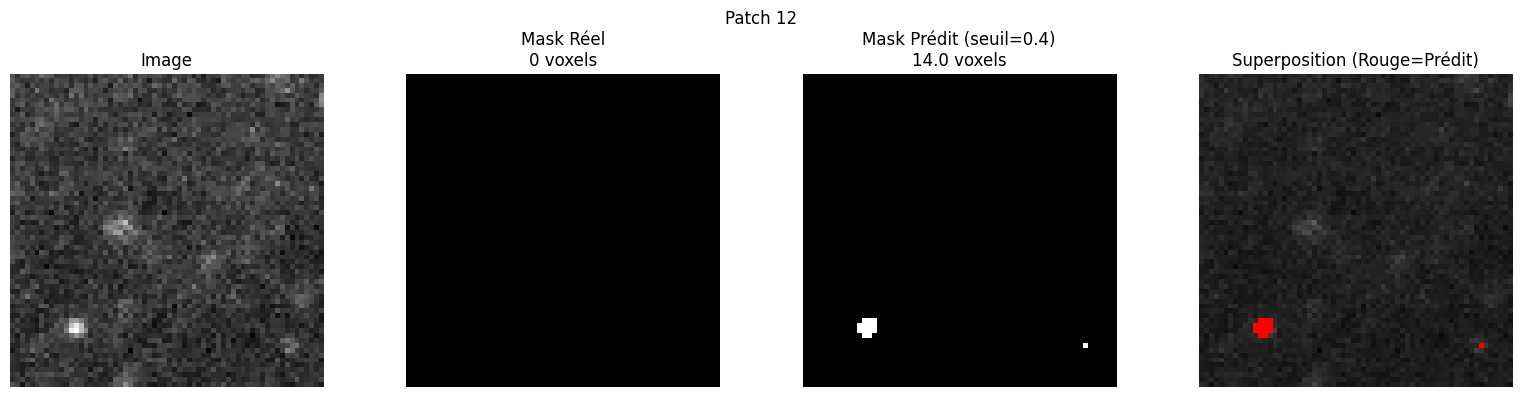

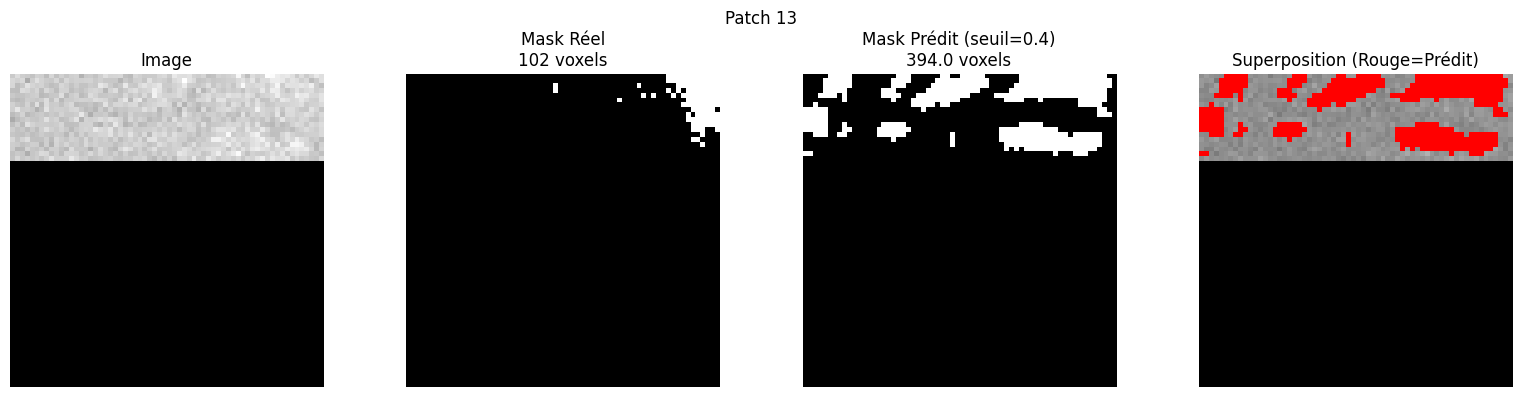

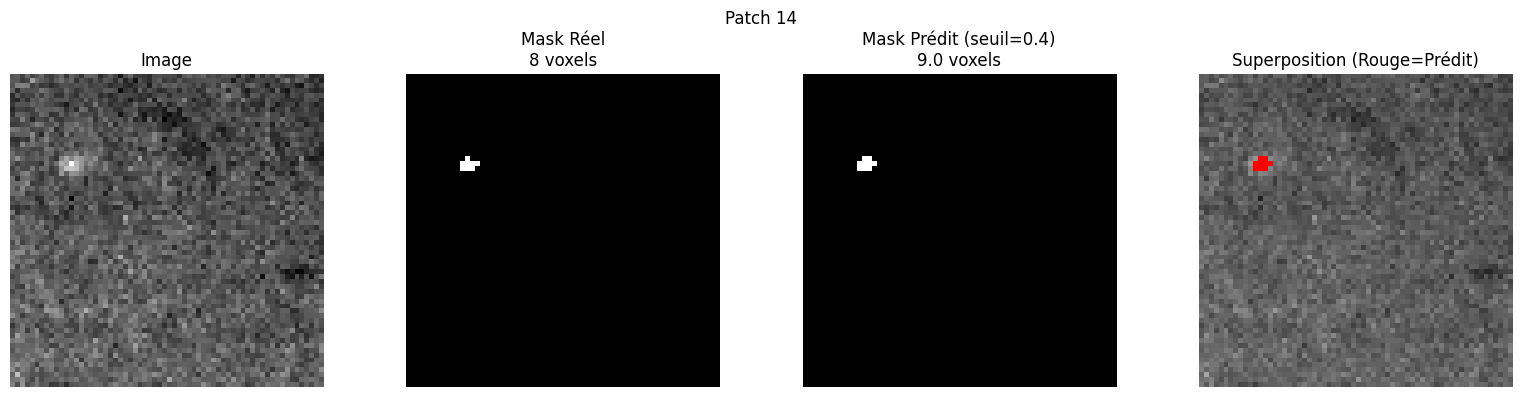

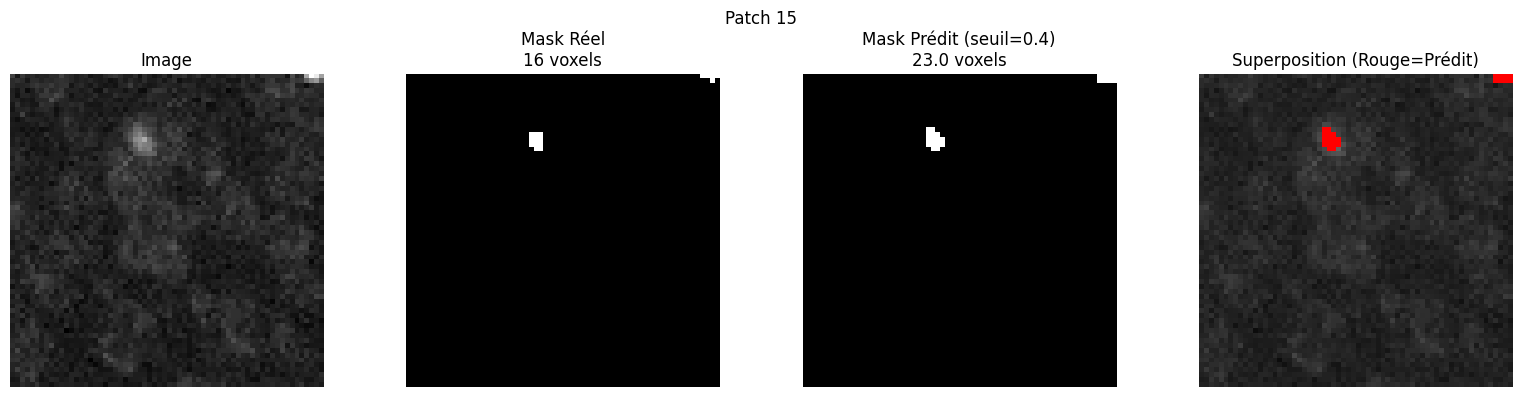

In [5]:
data_dir = Path("/mnt/x/donnees/pachs_64_2classes_slices40")
splits_dir = data_dir / "splits"

_, _, test_loader = create_datasets_2class(
    data_dir=data_dir,
    splits_dir=splits_dir,
    batch_size=4,
    num_workers=0
)

print(f"Nombre de patches de test: {len(test_loader.dataset)}")

SEUIL = 0.4

def predict_and_show_batch(loader, model, device, num_samples=15, seuil=0.3):
    model.eval()
    samples_shown = 0
    
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            
            preds = model(images)
            preds = torch.softmax(preds, dim=1)
            preds_class = (preds[:, 1, :, :, :] > seuil).float().cpu().numpy()
            
            images_np = images.cpu().numpy()
            masks_np = masks.cpu().numpy()
            
            for i in range(images_np.shape[0]):
                if samples_shown >= num_samples:
                    return
                
                img = images_np[i, 0, ...]
                mask_true = masks_np[i, 0, ...]
                mask_pred = preds_class[i, ...]
                
                slice_idx = img.shape[0] // 2
                
                img_slice = img[slice_idx, :, :]
                if img_slice.max() > 1:
                    img_slice = img_slice / img_slice.max()
                
                mask_true_slice = mask_true[slice_idx, :, :]
                mask_pred_slice = mask_pred[slice_idx, :, :]
                
                overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
                overlay[mask_pred_slice == 1, 0] = 1
                overlay[mask_pred_slice == 1, 1] = 0
                overlay[mask_pred_slice == 1, 2] = 0
                
                fig, axes = plt.subplots(1, 4, figsize=(16, 4))
                
                axes[0].imshow(img_slice, cmap='gray')
                axes[0].set_title('Image')
                axes[0].axis('off')
                
                axes[1].imshow(mask_true_slice, cmap='gray')
                axes[1].set_title(f'Mask Réel\n{np.sum(mask_true_slice)} voxels')
                axes[1].axis('off')
                
                axes[2].imshow(mask_pred_slice, cmap='gray')
                axes[2].set_title(f'Mask Prédit (seuil={seuil})\n{np.sum(mask_pred_slice)} voxels')
                axes[2].axis('off')
                
                axes[3].imshow(overlay)
                axes[3].set_title('Superposition (Rouge=Prédit)')
                axes[3].axis('off')
                
                plt.suptitle(f'Patch {samples_shown+1}')
                plt.tight_layout()
                plt.show()
                
                samples_shown += 1

print(f"Visualisation des prédictions sur le test set (seuil={SEUIL})...")
predict_and_show_batch(test_loader, model, device, num_samples=15, seuil=SEUIL)


Calcul de la matrice de confusion sur 50 patches de test...


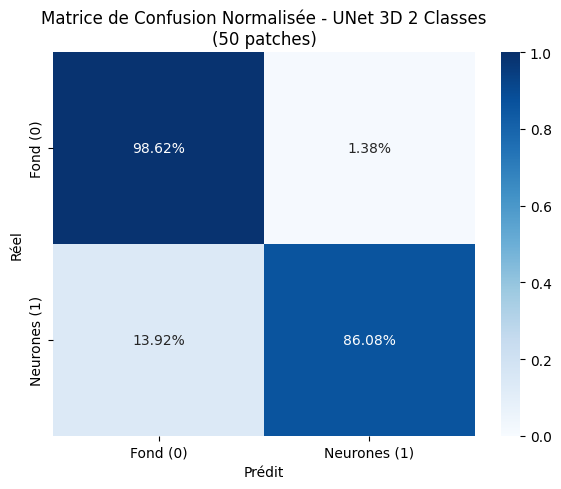

MATRICE DE CONFUSION - UNET 3D 2 CLASSES (50 patches)
Vrais Positifs (TP): 147,017
Faux Positifs (FP): 178,969
Faux Négatifs (FN): 23,771
Vrais Négatifs (TN): 12,757,443
Précision: 0.4510
Rappel: 0.8608
Accuracy: 0.9845


In [6]:
# Matrice de confusion 
from sklearn.metrics import confusion_matrix
import seaborn as sns

print("Calcul de la matrice de confusion sur 50 patches de test...")

all_true = []
all_pred = []
patches_count = 0

model.eval()
SEUIL = 0.3

with torch.no_grad():
    for images, masks in test_loader:
        if patches_count >= 50:
            break
        
        images = images.to(device)
        masks = masks.to(device)
        
        preds = model(images)
        preds = torch.softmax(preds, dim=1)
        preds_class = (preds[:, 1, :, :, :] > SEUIL).float().cpu().numpy()
        
        batch_size = images.shape[0]
        for i in range(batch_size):
            if patches_count >= 50:
                break
            all_true.extend(masks[i].cpu().numpy().flatten())
            all_pred.extend(preds_class[i].flatten())
            patches_count += 1

all_true = np.array(all_true)
all_pred = np.array(all_pred)

all_pred_bin = (all_pred > 0.5).astype(int)
all_true_bin = all_true.astype(int)

cm = confusion_matrix(all_true_bin, all_pred_bin)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Fond (0)', 'Neurones (1)'],
            yticklabels=['Fond (0)', 'Neurones (1)'],
            ax=ax, vmin=0, vmax=1)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title('Matrice de Confusion Normalisée - UNet 3D 2 Classes\n(50 patches)')

plt.tight_layout()
plt.show()

print("=" * 50)
print("MATRICE DE CONFUSION - UNET 3D 2 CLASSES (50 patches)")
print("=" * 50)
print(f"Vrais Positifs (TP): {cm[1,1]:,}")
print(f"Faux Positifs (FP): {cm[0,1]:,}")
print(f"Faux Négatifs (FN): {cm[1,0]:,}")
print(f"Vrais Négatifs (TN): {cm[0,0]:,}")
print(f"Précision: {cm[1,1]/(cm[1,1]+cm[0,1]) if (cm[1,1]+cm[0,1])>0 else 0:.4f}")
print(f"Rappel: {cm[1,1]/(cm[1,1]+cm[1,0]) if (cm[1,1]+cm[1,0])>0 else 0:.4f}")
print(f"Accuracy: {(cm[0,0]+cm[1,1])/cm.sum():.4f}")

In [9]:
def pad_to_multiple(image, patch_size=64):
    current_shape = image.shape
    new_shape = []
    pads = []
    
    for dim in range(3):
        remainder = current_shape[dim] % patch_size
        if remainder == 0:
            new_shape.append(current_shape[dim])
            pads.append(0)
        else:
            pad = patch_size - remainder
            new_shape.append(current_shape[dim] + pad)
            pads.append(pad)
    
    new_shape = tuple(new_shape)
    pad_width = [(0, pads[0]), (0, pads[1]), (0, pads[2])]
    padded_image = np.pad(image, pad_width=pad_width, mode='constant', constant_values=0)
    
    return padded_image, pads, new_shape

def extract_patches_3d(image, patch_size=64):
    patches = []
    coords = []
    
    z_steps = image.shape[0] // patch_size
    y_steps = image.shape[1] // patch_size
    x_steps = image.shape[2] // patch_size
    
    for z in range(z_steps):
        for y in range(y_steps):
            for x in range(x_steps):
                z_start = z * patch_size
                y_start = y * patch_size
                x_start = x * patch_size
                
                patch = image[
                    z_start:z_start + patch_size,
                    y_start:y_start + patch_size,
                    x_start:x_start + patch_size
                ]
                patches.append(patch)
                coords.append((z_start, y_start, x_start))
    
    return patches, coords

def reconstruct_from_patches(patches, coords, original_shape, patch_size=64):
    reconstructed = np.zeros(original_shape, dtype=np.float32)
    weights = np.zeros(original_shape, dtype=np.float32)
    
    for patch, (z_start, y_start, x_start) in zip(patches, coords):
        reconstructed[
            z_start:z_start + patch_size,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] += patch
        weights[
            z_start:z_start + patch_size,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] += 1
    
    weights[weights == 0] = 1
    reconstructed = reconstructed / weights
    
    return reconstructed

def save_array(array, file_path):
    sitk_image = sitk.GetImageFromArray(array.astype(np.uint8))
    sitk.WriteImage(sitk_image, str(file_path))

In [10]:
image_path = Path("/mnt/x/donnees/images_test/images/image.tif")
mask_path = Path("/mnt/x/donnees/images_test/masks_2_classe/mask_2_classes.tif")
output_path = Path("/mnt/x/donnees/images_test/unet2_classes_prediction/mask_unet_2_classes_predit.tif")
output_path.parent.mkdir(parents=True, exist_ok=True)

print("Chargement de l'image brute...")
image_sitk = read_tif_image(str(image_path))
image = convert_image_to_array(image_sitk)
mask_sitk = read_tif_image(str(mask_path))
mask_true = convert_image_to_array(mask_sitk)

print(f"Image shape: {image.shape}")
print(f"Mask shape: {mask_true.shape}")

PATCH_SIZE = 64
padded_image, pads, padded_shape = pad_to_multiple(image, PATCH_SIZE)
print(f"Image originale: {image.shape}")
print(f"Image paddée: {padded_shape}")

patches, coords = extract_patches_3d(padded_image, PATCH_SIZE)
print(f"Nombre de patches: {len(patches)}")

print("Prédiction en cours...")
predictions = []
SEUIL = 0.35

with torch.no_grad():
    for patch in tqdm(patches, desc="Patches"):
        patch_norm = patch.astype(np.float32)
        min_val = patch_norm.min()
        max_val = patch_norm.max()
        if max_val - min_val > 0:
            patch_norm = (patch_norm - min_val) / (max_val - min_val)
        else:
            patch_norm = np.zeros_like(patch_norm)
        
        patch_tensor = torch.from_numpy(patch_norm).float()
        patch_tensor = patch_tensor.unsqueeze(0).unsqueeze(0).to(device)
        
        pred = model(patch_tensor)
        pred = torch.softmax(pred, dim=1)
        pred = pred.cpu().numpy().squeeze()
        
        pred_class = (pred[1, :, :, :] > SEUIL).astype(np.float32)
        predictions.append(pred_class)

reconstructed = reconstruct_from_patches(predictions, coords, padded_shape, PATCH_SIZE)

if pads[0] > 0:
    reconstructed = reconstructed[:-pads[0], :, :]
if pads[1] > 0:
    reconstructed = reconstructed[:, :-pads[1], :]
if pads[2] > 0:
    reconstructed = reconstructed[:, :, :-pads[2]]

print(f"Image reconstruite: {reconstructed.shape}")
save_array(reconstructed, output_path)
print(f"Mask sauvegardé: {output_path}")

Chargement de l'image brute...
Image shape: (299, 634, 580)
Mask shape: (299, 634, 580)
Image originale: (299, 634, 580)
Image paddée: (320, 640, 640)
Nombre de patches: 500
Prédiction en cours...


Patches: 100%|███████████████████████████████████████████████████████████| 500/500 [00:07<00:00, 65.28it/s]


Image reconstruite: (299, 634, 580)
Mask sauvegardé: /mnt/x/donnees/images_test/unet2_classes_prediction/mask_unet_2_classes_predit.tif


Visualisation de l'image brute et du mask prédit...


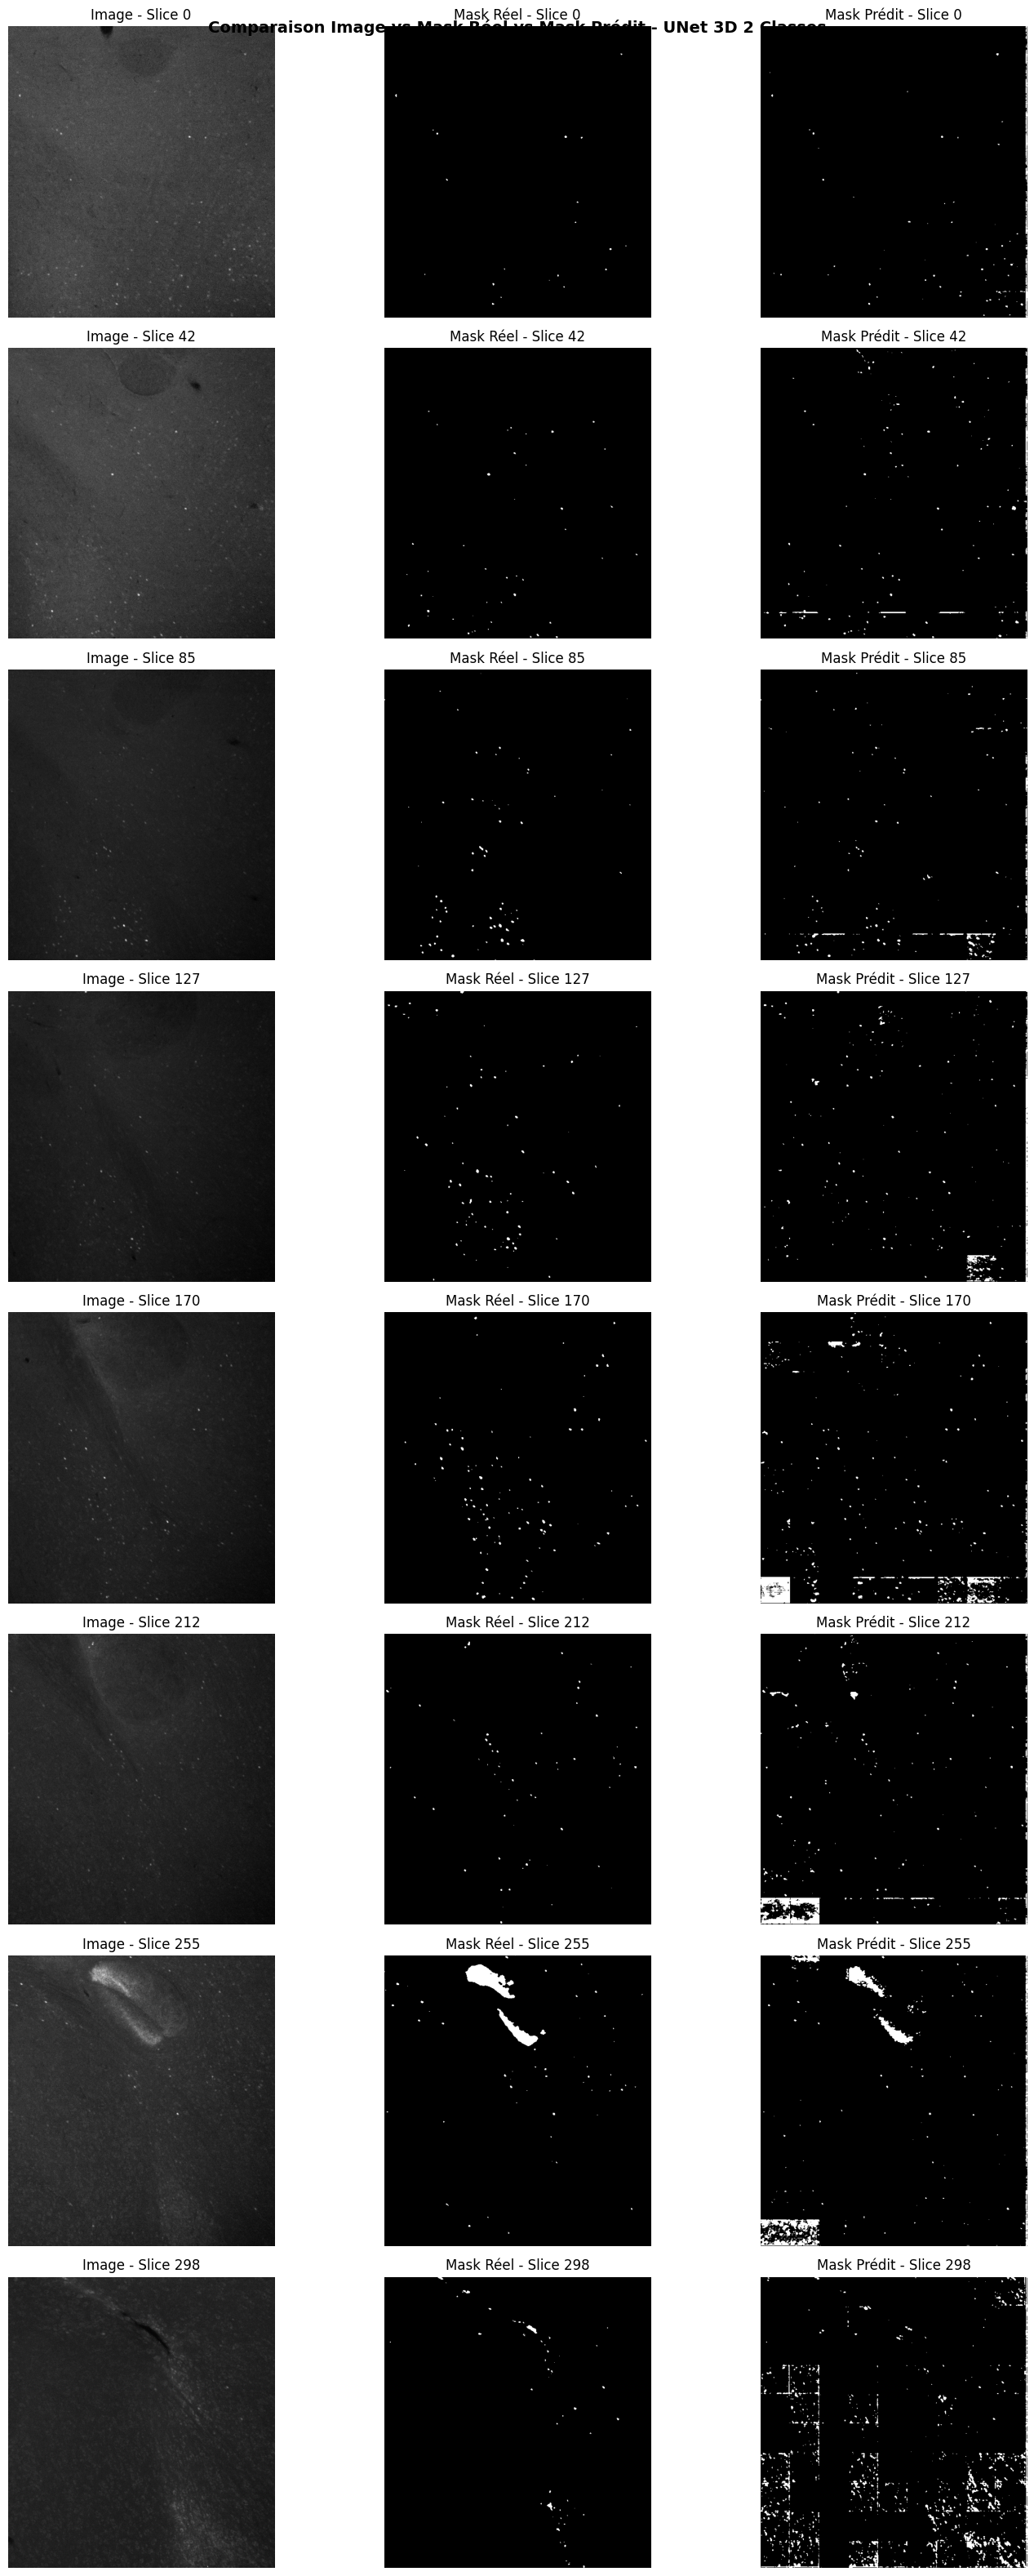

In [12]:
def visualize_slices(image, mask_true, mask_pred, num_slices=6):
    total_z = image.shape[0]
    slice_indices = np.linspace(0, total_z - 1, num_slices, dtype=int)
    
    fig, axes = plt.subplots(num_slices, 3, figsize=(15, 4*num_slices))
    
    for i, z_idx in enumerate(slice_indices):
        img_slice = image[z_idx, :, :]
        if img_slice.max() > 1:
            img_slice = img_slice / img_slice.max()
        
        axes[i, 0].imshow(img_slice, cmap='gray')
        axes[i, 0].set_title(f'Image - Slice {z_idx}')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(mask_true[z_idx, :, :], cmap='gray')
        axes[i, 1].set_title(f'Mask Réel - Slice {z_idx}')
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(mask_pred[z_idx, :, :], cmap='gray')
        axes[i, 2].set_title(f'Mask Prédit - Slice {z_idx}')
        axes[i, 2].axis('off')
    
    plt.suptitle('Comparaison Image vs Mask Réel vs Mask Prédit - UNet 3D 2 Classes', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("Visualisation de l'image brute et du mask prédit...")
visualize_slices(image, mask_true, reconstructed, num_slices=8)

In [13]:
pred_neurons = (reconstructed == 1).sum()
true_neurons = (mask_true == 1).sum()

print("=" * 60)
print("STATISTIQUES DE L'IMAGE PRÉDITE - UNET 3D 2 CLASSES")
print("=" * 60)
print(f"Image shape: {image.shape}")
print(f"Mask shape: {reconstructed.shape}")
print()
print(f"Neurones réels: {true_neurons}")
print(f"Neurones prédits: {pred_neurons}")
print(f"Ratio: {pred_neurons / true_neurons if true_neurons > 0 else 0:.2f}")
print()
print(f"Padding ajouté: {pads}")
print(f"Patches créés: {len(patches)}")
print(f"Mask sauvegardé: {output_path}")
print("=" * 60)

STATISTIQUES DE L'IMAGE PRÉDITE - UNET 3D 2 CLASSES
Image shape: (299, 634, 580)
Mask shape: (299, 634, 580)

Neurones réels: 408836
Neurones prédits: 4685016
Ratio: 11.46

Padding ajouté: [21, 6, 60]
Patches créés: 500
Mask sauvegardé: /mnt/x/donnees/images_test/unet2_classes_prediction/mask_unet_2_classes_predit.tif
